### Feature Engineering

In [4]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, median_absolute_error
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error, mean_absolute_percentage_error

df = pd.read_csv('../../data/prepared_energy_dataset.csv')
df_copy = df.copy()

In [18]:
correlation = df['Throughput_Mbps'].corr(df['Traffic_Volume_Mbps'])
print(f"Correlation between Throughput and Traffic: {correlation:.4f}")

cols_to_drop = [
    'Throughput_Mbps',
    'Record_ID', 'Timestamp', 'split', 'Month',
    'Predicted_Energy_Requirement_kWh', 'Energy_Management_Status', 
    'Energy_Consumption_kWh', 'Energy_Efficiency_Mbps_per_kWh', 
    'Carbon_Emission_kg', 'Operational_Cost_USD',
    'Network_Condition', 'Congestion_Index', 'QoS_Satisfaction_Score', 
    'SLA_Violation_Count', 'Future_Congestion_Index'
]

df_final = df_copy.drop(columns=cols_to_drop, errors='ignore')

train_df = df_final[df['split'] == 'train'].copy()
val_df = df_final[df['split'] == 'val'].copy()
test_df = df_final[df['split'] == 'test'].copy()

target = 'Total_Power_Watt'

X_train_A = train_df.drop(columns=[target])
y_train_A = train_df[target]

X_val_A = val_df.drop(columns=[target])
y_val_A = val_df[target]

X_test_A = test_df.drop(columns=[target])
y_test_A = test_df[target]

print(f"Final Task A Training Features: {X_train_A.shape[1]}") 

X_train_A.to_csv('../../data/X_train_taskA.csv', index=False)
X_val_A.to_csv('../../data/X_val_taskA.csv', index=False)
X_test_A.to_csv('../../data/X_test_taskA.csv', index=False)

y_train_A.to_csv('../../data/y_train_taskA.csv', index=False)
y_val_A.to_csv('../../data/y_val_taskA.csv', index=False)
y_test_A.to_csv('../../data/y_test_taskA.csv', index=False)

Correlation between Throughput and Traffic: 0.9912
Final Task A Training Features: 32


### Baseline model


In [2]:
X_train = pd.read_csv('../../data/X_train_taskA.csv')
X_val = pd.read_csv('../../data/X_val_taskA.csv')
y_train = pd.read_csv('../../data/y_train_taskA.csv').squeeze()
y_val = pd.read_csv('../../data/y_val_taskA.csv').squeeze()

X_train_nodes_only = X_train[['Active_Core_Nodes']]
X_val_nodes_only = X_val[['Active_Core_Nodes']]

In [6]:
mean_model = DummyRegressor(strategy="mean")
mean_model.fit(X_train, y_train)
mean_preds = mean_model.predict(X_val)
mean_mse = mean_squared_error(y_val, mean_preds)
mean_rmse = np.sqrt(mean_mse)
mean_rmse_pct = (mean_rmse / y_val.mean()) * 100
mean_mape_pct = mean_absolute_percentage_error(y_val, mean_preds) * 100

print("--- 1. Mean Baseline ---")
print(f"MAE: {mean_absolute_error(y_val, mean_preds):.1f} W")
print(f"R2:  {r2_score(y_val, mean_preds):.3f}")
print(f"RMSE (Normalized): {mean_rmse_pct:.1f}%")
print(f"MAPE: {mean_mape_pct:.1f}%\n")

linear_model = LinearRegression()
linear_model.fit(X_train_nodes_only, y_train)
linear_preds = linear_model.predict(X_val_nodes_only)

mse = mean_squared_error(y_val, linear_preds)
rmse = np.sqrt(mse)
rmse_pct = (rmse / y_val.mean()) * 100
mape_pct = mean_absolute_percentage_error(y_val, linear_preds) * 100

print("--- 2. Nodes-Only Linear Model ---")
print(f"MAE: {mean_absolute_error(y_val, linear_preds):.1f} W")
print(f"R2:  {r2_score(y_val, linear_preds):.3f}")
print(f"RMSE (Normalized): {rmse_pct:.1f}%")
print(f"MAPE: {mape_pct:.1f}%")

intercept = linear_model.intercept_
coefficient = linear_model.coef_[0]
print(f"\nLearned Formula: Power = {intercept:.0f} W + {coefficient:.1f} W x active_nodes")

--- 1. Mean Baseline ---
MAE: 233.7 W
R2:  -0.000
RMSE (Normalized): 21.3%
MAPE: 17.2%

--- 2. Nodes-Only Linear Model ---
MAE: 157.9 W
R2:  0.582
RMSE (Normalized): 13.8%
MAPE: 11.8%

Learned Formula: Power = 769 W + 110.1 W x active_nodes


### Advanced Model

In [ ]:
X_train = pd.read_csv('../../data/X_train_taskA.csv')
X_val = pd.read_csv('../../data/X_val_taskA.csv')

y_train = pd.read_csv('../../data/y_train_taskA.csv').squeeze()
y_val = pd.read_csv('../../data/y_val_taskA.csv').squeeze()

print(f"Training on all {X_train.shape[1]} features.")

Training on all 32 features.


In [8]:
categorical_cols = X_train.select_dtypes(include=['object']).columns.tolist()
numerical_cols = X_train.select_dtypes(exclude=['object']).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numerical_cols),
    ('cat', categorical_transformer, categorical_cols)
])

/var/folders/t9/5qyb5pw554s_w_jt9c13myrh0000gn/T/ipykernel_77004/3534175249.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X_train.select_dtypes(include=['object']).columns.tolist()


In [9]:
xgb_model = XGBRegressor(n_estimators=200, max_depth=4, learning_rate=0.1, random_state=42)

advanced_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', xgb_model)
])

advanced_pipeline.fit(X_train, y_train)
xgb_preds = advanced_pipeline.predict(X_val)
xgb_mae = mean_absolute_error(y_val, xgb_preds)
xgb_r2 = r2_score(y_val, xgb_preds)

xgb_mse = mean_squared_error(y_val, xgb_preds)
xgb_rmse = np.sqrt(xgb_mse)
xgb_rmse_pct = (xgb_rmse / y_val.mean()) * 100
xgb_mape_pct = mean_absolute_percentage_error(y_val, xgb_preds) * 100

print("\n--- Advanced Model (XGBoost) ---")
print(f"MAE: {xgb_mae:.1f} W")
print(f"R2:  {xgb_r2:.3f}")
print(f"RMSE (Normalized): {xgb_rmse_pct:.1f}%")
print(f"MAPE: {xgb_mape_pct:.1f}%")


--- Advanced Model (XGBoost) ---
MAE: 148.2 W
R2:  0.644
RMSE (Normalized): 12.7%
MAPE: 11.1%


#### Advanced Modeling Strategy: What & Why

**1. The Algorithm: XGBoost (Extreme Gradient Boosting)**
* **The Technique:** An ensemble learning method that builds multiple Decision Trees sequentially. Each new tree specifically tries to correct the mathematical errors made by the previous trees.
* **Why we used it:** While our Simple Linear Regression baseline only understood straight lines (assuming power scales perfectly linearly with nodes), XGBoost captures complex, non-linear relationships. For example, it can learn that CPU usage might only spike power consumption *after* it crosses an 80% threshold.

**2. The Reintroduction of the Pipeline**
* **The Technique:** Scikit-learn `Pipeline` and `ColumnTransformer`.
* **Why we used it here:** Unlike the baseline which only used one raw numerical column, our Advanced Model uses all 32 features. We reintroduced the Pipeline to strictly enforce Data Leakage prevention. By bundling the Imputers, Scalers, and Encoders directly with the XGBoost algorithm, we guarantee that the Validation set is never used to calculate scaling averages or median values.

### Hyperparameter tuning

In [11]:
# 1. Load Data
X_train = pd.read_csv('../../data/X_train_taskA.csv')
y_train = pd.read_csv('../../data/y_train_taskA.csv').squeeze()

# 2. Build Preprocessor (same as before)
categorical_cols = X_train.select_dtypes(include=['object']).columns.tolist()
numerical_cols = X_train.select_dtypes(exclude=['object']).columns.tolist()

preprocessor = ColumnTransformer(transformers=[
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), numerical_cols),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('enc', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), categorical_cols)
])

# 3. Define the Time-Series Split (4 splits as requested by the document)
tscv = TimeSeriesSplit(n_splits=4)

print("Data, Preprocessor, and Time-Series Splitter ready.")

Data, Preprocessor, and Time-Series Splitter ready.


/var/folders/t9/5qyb5pw554s_w_jt9c13myrh0000gn/T/ipykernel_77004/3900939075.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X_train.select_dtypes(include=['object']).columns.tolist()


In [13]:
import time

ridge_pipe = Pipeline([('prep', preprocessor), ('reg', Ridge())])
rf_pipe = Pipeline([('prep', preprocessor), ('reg', RandomForestRegressor(random_state=42, n_jobs=-1))])
xgb_pipe = Pipeline([('prep', preprocessor), ('reg', XGBRegressor(random_state=42))])

ridge_params = {'reg__alpha': [0.1, 1, 10, 100, 1000]}
rf_params = {'reg__n_estimators': [150, 250], 'reg__max_depth': [4, 6, 8, None], 'reg__min_samples_leaf': [5, 20, 50]}
xgb_params = {'reg__n_estimators': [100, 200, 300], 'reg__max_depth': [2, 3, 4, 6], 'reg__learning_rate': [0.02, 0.05, 0.1]}

models_to_tune = {
    'Ridge': (ridge_pipe, ridge_params, 5),
    'Random Forest': (rf_pipe, rf_params, 6),
    'XGBoost': (xgb_pipe, xgb_params, 12)
}

start_time = time.time()
best_models = {}

for name, (pipe, params, n_iter) in models_to_tune.items():
    print(f"Tuning {name}...")
    search = RandomizedSearchCV(
        estimator=pipe, param_distributions=params, n_iter=n_iter,
        scoring='neg_mean_absolute_error', cv=tscv, random_state=42, n_jobs=-1
    )
    search.fit(X_train, y_train)
    best_models[name] = search.best_estimator_
    
    val_preds = search.best_estimator_.predict(X_val)
    val_rmse = np.sqrt(mean_squared_error(y_val, val_preds))
    val_rmse_pct = (val_rmse / y_val.mean()) * 100
    val_mape_pct = mean_absolute_percentage_error(y_val, val_preds) * 100

    best_cv_mae = -search.best_score_
    clean_params = {k.replace('reg__', ''): v for k, v in search.best_params_.items()}
    
    print(f"{name}: best CV MAE = {best_cv_mae:.1f} W | params = {clean_params}")
    print(f"  -> Val RMSE (Norm): {val_rmse_pct:.1f}% | Val MAPE: {val_mape_pct:.1f}%\n")

print(f"Tuning time: {time.time() - start_time:.0f} s")

Tuning Ridge...
Ridge: best CV MAE = 146.9 W | params = {'alpha': 10}
  -> Val RMSE (Norm): 12.5% | Val MAPE: 11.0%

Tuning Random Forest...
Random Forest: best CV MAE = 148.3 W | params = {'n_estimators': 250, 'min_samples_leaf': 20, 'max_depth': 6}
  -> Val RMSE (Norm): 12.6% | Val MAPE: 11.0%

Tuning XGBoost...
XGBoost: best CV MAE = 148.0 W | params = {'n_estimators': 100, 'max_depth': 2, 'learning_rate': 0.05}
  -> Val RMSE (Norm): 12.5% | Val MAPE: 11.0%

Tuning time: 15 s


### Validation and Evaluation

In [15]:
X_train = pd.read_csv('../../data/X_train_taskA.csv')
X_val = pd.read_csv('../../data/X_val_taskA.csv')
X_test = pd.read_csv('../../data/X_test_taskA.csv')

y_train = pd.read_csv('../../data/y_train_taskA.csv').squeeze()
y_val = pd.read_csv('../../data/y_val_taskA.csv').squeeze()
y_test = pd.read_csv('../../data/y_test_taskA.csv').squeeze()

X_train_val = pd.concat([X_train, X_val], ignore_index=True)
y_train_val = pd.concat([y_train, y_val], ignore_index=True)

print(f"Combined Training Data Shape: {X_train_val.shape}")
print(f"Unseen Test Data Shape: {X_test.shape}")

Combined Training Data Shape: (12750, 32)
Unseen Test Data Shape: (2250, 32)


In [ ]:
from sklearn.metrics import mean_absolute_percentage_error

categorical_cols = X_train_val.select_dtypes(include=['object']).columns.tolist()
numerical_cols = X_train_val.select_dtypes(exclude=['object']).columns.tolist()

preprocessor = ColumnTransformer(transformers=[
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), numerical_cols),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('enc', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), categorical_cols)
])

final_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', XGBRegressor(n_estimators=300, max_depth=3, learning_rate=0.02,subsample=0.9, colsample_bytree=0.6, random_state=42))
])

print("Refitting final model on Train+Val data...")
final_model.fit(X_train_val, y_train_val)

test_preds = final_model.predict(X_test)

mae = mean_absolute_error(y_test, test_preds)
rmse = np.sqrt(mean_squared_error(y_test, test_preds))
r2 = r2_score(y_test, test_preds)
medae = median_absolute_error(y_test, test_preds)

rmse_pct = (rmse / y_test.mean()) * 100
mape_pct = mean_absolute_percentage_error(y_test, test_preds) * 100

print("\n--- Final Test Set Performance (XGBoost) ---")
print(f"MAE:   {mae:.1f} W")
print(f"RMSE:  {rmse:.1f} W")
print(f"RMSE (Normalized): {rmse_pct:.1f}%")
print(f"R2:    {r2:.3f}")
print(f"MedAE: {medae:.1f} W")
print(f"MAPE:  {mape_pct:.1f}%")

/var/folders/t9/5qyb5pw554s_w_jt9c13myrh0000gn/T/ipykernel_77004/2818325262.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X_train_val.select_dtypes(include=['object']).columns.tolist()


Refitting final model on Train+Val data...

--- Final Test Set Performance (XGBoost) ---
MAE:   143.4 W
RMSE:  174.2 W
RMSE (Normalized): 12.3%
R2:    0.663
MedAE: 130.8 W
MAPE:  10.6%


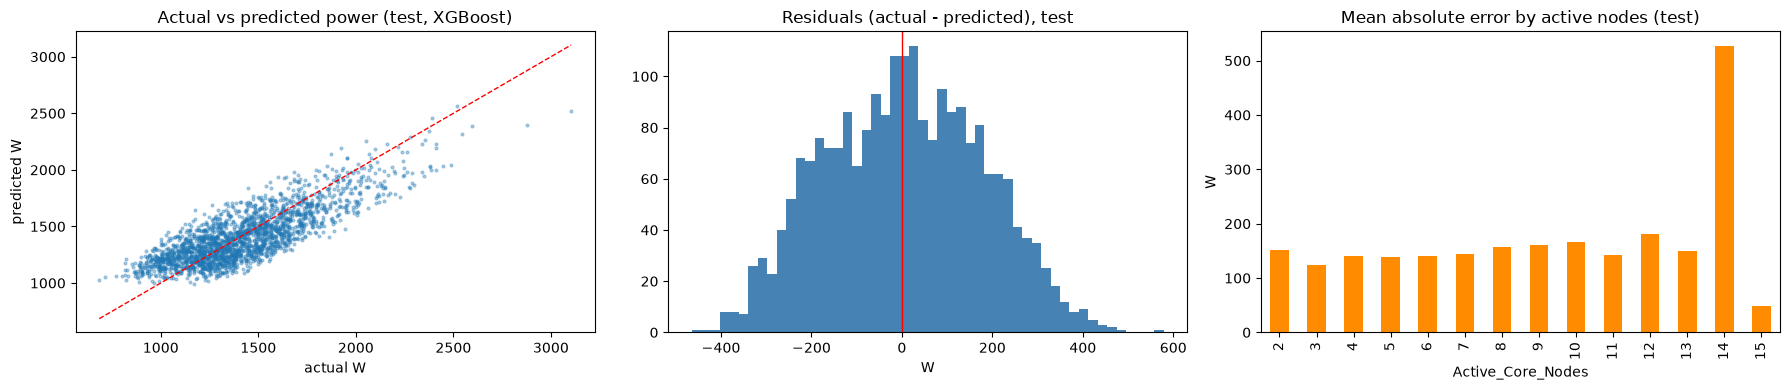

Residual mean 5.6 W, sd 174.1 W | share of test rows with |error| < 100 W: 38.9%, < 200 W: 71.8%


In [17]:
import matplotlib.pyplot as plt

residuals = y_test - test_preds
abs_error = np.abs(residuals)

fig, ax = plt.subplots(1, 3, figsize=(18, 4))

ax[0].scatter(y_test, test_preds, s=4, alpha=0.35)
lim_min, lim_max = y_test.min(), y_test.max()
ax[0].plot([lim_min, lim_max], [lim_min, lim_max], 'r--', lw=1) 
ax[0].set_title('Actual vs predicted power (test, XGBoost)')
ax[0].set_xlabel('actual W')
ax[0].set_ylabel('predicted W')

ax[1].hist(residuals, bins=50, color='steelblue')
ax[1].axvline(0, color='r', lw=1) # Zero error line
ax[1].set_title('Residuals (actual - predicted), test')
ax[1].set_xlabel('W')

error_df = pd.DataFrame({'Active_Core_Nodes': X_test['Active_Core_Nodes'].values, 'Absolute_Error': abs_error.values})
mae_by_node = error_df.groupby('Active_Core_Nodes')['Absolute_Error'].mean()

mae_by_node.plot(kind='bar', ax=ax[2], color='darkorange')
ax[2].set_title('Mean absolute error by active nodes (test)')
ax[2].set_ylabel('W')

plt.tight_layout()
plt.show()

pct_under_100 = (abs_error < 100).mean() * 100
pct_under_200 = (abs_error < 200).mean() * 100
print(f"Residual mean {residuals.mean():.1f} W, sd {residuals.std():.1f} W | share of test rows with |error| < 100 W: {pct_under_100:.1f}%, < 200 W: {pct_under_200:.1f}%")

Calculating permutation importance (this may take a moment)...


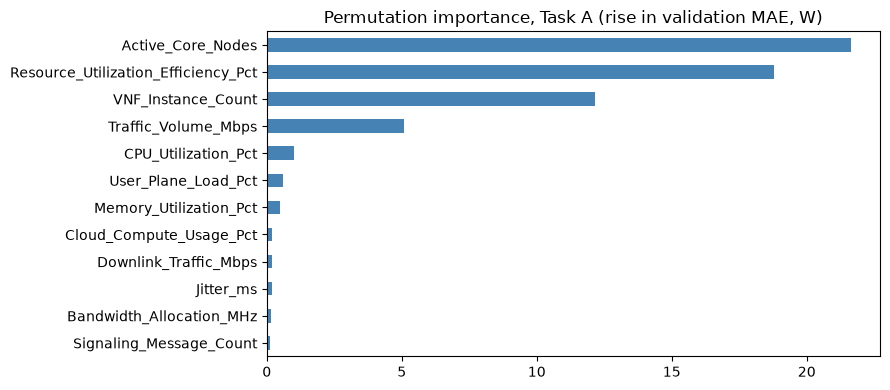

Top 8: {'Active_Core_Nodes': 21.63, 'Resource_Utilization_Efficiency_Pct': 18.79, 'VNF_Instance_Count': 12.15, 'Traffic_Volume_Mbps': 5.09, 'CPU_Utilization_Pct': 1.01, 'User_Plane_Load_Pct': 0.6, 'Memory_Utilization_Pct': 0.49, 'Cloud_Compute_Usage_Pct': 0.2}
Features with importance <= 0: 2 of 32


In [ ]:
from sklearn.inspection import permutation_importance

print("Calculating permutation importance (this may take a moment)...")
pi = permutation_importance(final_model, X_val, y_val, scoring='neg_mean_absolute_error', n_repeats=5, random_state=42, n_jobs=-1)

importance_df = pd.Series(pi.importances_mean, index=X_val.columns).sort_values(ascending=False)
top_12_features = importance_df.head(12)

fig, ax = plt.subplots(figsize=(9, 4))
top_12_features.sort_values(ascending=True).plot(kind='barh', ax=ax, color='steelblue')
ax.set_title('Permutation importance, Task A (rise in validation MAE, W)')
plt.tight_layout()
plt.show()

print(f"Top 8: {importance_df.head(8).round(2).to_dict()}")

zero_importance = (importance_df <= 0).sum()
print(f"Features with importance <= 0: {zero_importance} of {len(importance_df)}")